# Analysis: GP-BO vs CMA-ES

Reads the saved runs in `results/<method>/` and compares methods across effective dimension and orientation.
This notebook does not run any optimiser.

**Hypotheses**
- **H1 (rotation):** ARD-BO has a larger rotation penalty than CMA-ES. ARD assigns a separate length scale to each input coordinate, whereas CMA-ES can adapt the orientation of its search distribution through a full covariance matrix (Rasmussen & Williams, 2006; Hansen, 2016).
- **H2 (effective dimension):** ARD-BO's rotation penalty tends to be greater at smaller effective dimensions. In the aligned case, more coordinates are irrelevant, giving ARD greater scope to down-weight them through large length scales (Rasmussen & Williams, 2006).
- **H3 (kernel comparison):** ARD-BO has a larger rotation penalty than isotropic BO. Rotation is expected to reduce ARD's benefit from learning separate length scales for individual coordinates.

**Rotation penalty** = log10(rotated final value / aligned final value), for the same method, d, problem seed and method seed.
Above 0 means rotation made the method worse; 1 means ten times worse.

## 1. Setup

In [28]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [29]:
RESULTS_DIR = Path("../results")

# Shared experimental settings (match code/cmaes.py and code/shared_bo.py).
D = 20
EFFECTIVE_DIMS = [2, 5, 10, 15, 20]
PROBLEM_SEEDS = [0, 1, 2, 3, 4]
METHOD_SEEDS = [100, 101]
BUDGET = 400

# Methods to compare: results folder name -> plot label.
METHODS = {
    "bo_ard": "GP-BO (ARD)",
    "isotropic_bo": "GP-BO (isotropic)",
    "cmaes": "CMA-ES",
    "random_search": "Random search",
}

## 2. Load results

Each CSV is one run with one row per evaluation. The filename pattern skips files such as `test_run.csv`.

In [30]:
KEY_COLUMNS = ["method", "d", "problem_seed", "rotated", "method_seed"]


def load_results(results_dir=RESULTS_DIR, methods=METHODS):
    """Combine every saved run into one long table (one row per evaluation)."""
    frames = []
    for method in methods:
        for path in sorted((results_dir / method).glob("d*_problem*_method*.csv")):
            frames.append(pd.read_csv(path))

    if not frames:
        raise FileNotFoundError(f"No result files found in {results_dir}.")

    df = pd.concat(frames, ignore_index=True)
    df["orientation"] = np.where(df["rotated"], "rotated", "aligned")
    return df

In [31]:
df = load_results()

# Only methods with saved results are compared below.
available = [m for m in METHODS if m in set(df["method"])]
print("Methods analysed:", [METHODS[m] for m in available])

Methods analysed: ['GP-BO (ARD)', 'GP-BO (isotropic)', 'CMA-ES', 'Random search']


### 2.1 Checks

Each method should have 5 dims x 5 problems x 2 orientations x 2 method seeds = 100 runs, each with 400 evaluations.

In [32]:
evals_per_run = df.groupby(KEY_COLUMNS).size()
bad_runs = evals_per_run[evals_per_run != BUDGET]
print("Runs without exactly", BUDGET, "evaluations:", len(bad_runs))

expected = len(EFFECTIVE_DIMS) * len(PROBLEM_SEEDS) * 2 * len(METHOD_SEEDS)
runs_per_method = evals_per_run.groupby("method").size()
print(f"\nRuns per method (expected {expected}):")
print(runs_per_method.rename(index=METHODS).to_string())

Runs without exactly 400 evaluations: 0

Runs per method (expected 100):
method
GP-BO (ARD)          100
CMA-ES               100
GP-BO (isotropic)    100
Random search        100


## 3. Convergence curves

Best value found against evaluations: one panel per effective dimension, aligned vs rotated, one line per method.

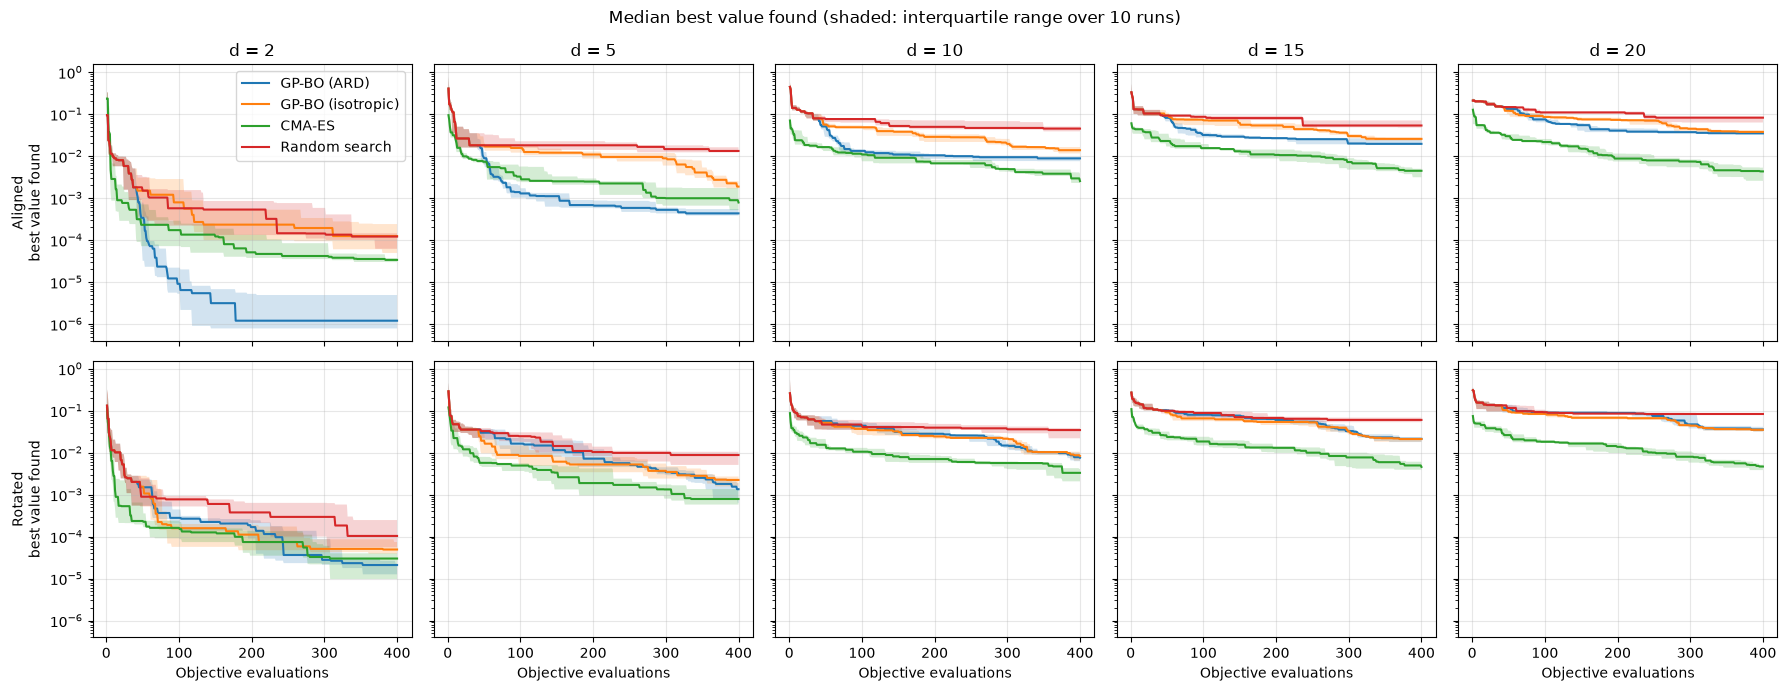

In [33]:
fig, axes = plt.subplots(
    2, len(EFFECTIVE_DIMS), figsize=(18, 7), sharex=True, sharey=True
)

for row, orientation in enumerate(["aligned", "rotated"]):
    for col, d in enumerate(EFFECTIVE_DIMS):
        ax = axes[row, col]
        subset = df[(df["d"] == d) & (df["orientation"] == orientation)]

        for method in available:
            curves = subset[subset["method"] == method].pivot_table(
                index="evaluation",
                columns=["problem_seed", "method_seed"],
                values="best_so_far",
            )
            q25, q50, q75 = (curves.quantile(q, axis=1) for q in (0.25, 0.5, 0.75))
            ax.plot(q50.index, q50, label=METHODS[method])
            ax.fill_between(q50.index, q25, q75, alpha=0.2)

        ax.set_yscale("log")
        ax.grid(True, alpha=0.3)
        if row == 0:
            ax.set_title(f"d = {d}")
        if row == 1:
            ax.set_xlabel("Objective evaluations")
        if col == 0:
            ax.set_ylabel(f"{orientation.capitalize()}\nbest value found")

axes[0, 0].legend()
fig.suptitle("Median best value found (shaded: interquartile range over 10 runs)")
plt.tight_layout()
plt.show()

## 4. Final performance

Summary of `best_so_far` at evaluation 400 (= simple regret, since the minimum is 0).

In [34]:
# One row per run: the best value after the full budget.
final = df[df["evaluation"] == BUDGET].copy()


def q25(x):
    return x.quantile(0.25)


def q75(x):
    return x.quantile(0.75)


summary = (
    final.groupby(["method", "d", "orientation"])["best_so_far"]
    .agg(median="median", q25=q25, q75=q75, mean="mean", runs="size")
    .reset_index()
)
summary["method"] = summary["method"].map(METHODS)

with pd.option_context("display.float_format", "{:.3g}".format):
    display(summary)

,method,d,orientation,median,q25,q75,mean,runs
0,GP-BO (ARD),2,aligned,1.2e-06,7.86e-07,4.91e-06,4.53e-06,10
1,GP-BO (ARD),2,rotated,2.1e-05,1.26e-05,2.28e-05,2.27e-05,10
2,GP-BO (ARD),5,aligned,0.000433,0.000384,0.000546,0.000445,10
3,GP-BO (ARD),5,rotated,0.00134,0.000632,0.00188,0.00172,10
4,GP-BO (ARD),10,aligned,0.00883,0.00757,0.00964,0.00827,10
5,GP-BO (ARD),10,rotated,0.00755,0.00625,0.00871,0.00908,10
6,GP-BO (ARD),15,aligned,0.0196,0.0184,0.0243,0.0212,10
7,GP-BO (ARD),15,rotated,0.0213,0.0178,0.0233,0.0238,10
8,GP-BO (ARD),20,aligned,0.0348,0.0342,0.0375,0.0358,10
9,GP-BO (ARD),20,rotated,0.0356,0.0317,0.0412,0.0446,10


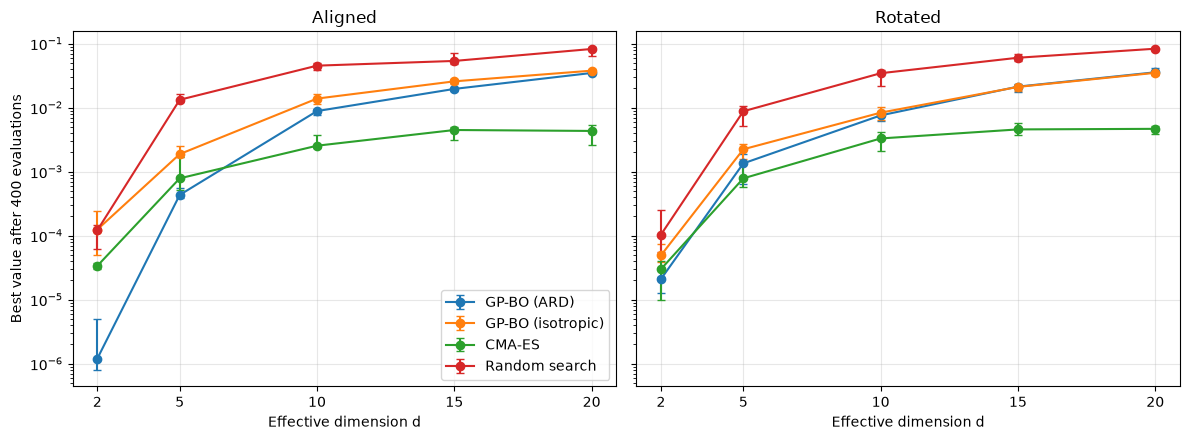

In [35]:
# Final best value against d, one line per method.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

for ax, orientation in zip(axes, ["aligned", "rotated"]):
    for method in available:
        values = final[(final["method"] == method) & (final["orientation"] == orientation)]
        stats = values.groupby("d")["best_so_far"].quantile([0.25, 0.5, 0.75]).unstack()
        ax.errorbar(
            stats.index,
            stats[0.5],
            yerr=[stats[0.5] - stats[0.25], stats[0.75] - stats[0.5]],
            marker="o",
            capsize=3,
            label=METHODS[method],
        )

    ax.set_yscale("log")
    ax.set_xticks(EFFECTIVE_DIMS)
    ax.set_title(orientation.capitalize())
    ax.set_xlabel("Effective dimension d")
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel(f"Best value after {BUDGET} evaluations")
axes[0].legend()
plt.tight_layout()
plt.show()

## 5. Rotation penalty

Each rotated run is matched with its aligned twin (same method, d, problem seed and method seed).
Above 0: rotation made the method worse.

In [36]:
# Match each rotated run with its aligned twin (same method, d and seeds).
pairs = final.pivot_table(
    index=["method", "d", "problem_seed", "method_seed"],
    columns="rotated",
    values="best_so_far",
).rename(columns={False: "aligned", True: "rotated"})

# > 0: rotation made the method worse; 1 = ten times worse.
pairs["log10_rotation_effect"] = np.log10(pairs["rotated"] / pairs["aligned"])
pairs = pairs.reset_index()

rotation_summary = (
    pairs.groupby(["method", "d"])["log10_rotation_effect"]
    .agg(median="median", q25=q25, q75=q75)
    .join(
        pairs.groupby(["method", "d"])["log10_rotation_effect"]
        .apply(lambda x: (x > 0).mean())
        .rename("fraction_worse_when_rotated")
    )
    .reset_index()
)
rotation_summary["method"] = rotation_summary["method"].map(METHODS)

with pd.option_context("display.float_format", "{:.2f}".format):
    display(rotation_summary)

,method,d,median,q25,q75,fraction_worse_when_rotated
0,GP-BO (ARD),2,1.25,0.42,1.41,0.90
1,GP-BO (ARD),5,0.39,0.11,0.65,1.00
2,GP-BO (ARD),10,0.04,-0.14,0.11,0.60
3,GP-BO (ARD),15,-0.06,-0.09,0.12,0.40
4,GP-BO (ARD),20,-0.02,-0.04,0.08,0.40
5,CMA-ES,2,-0.24,-0.38,0.11,0.30
6,CMA-ES,5,-0.07,-0.21,0.33,0.40
7,CMA-ES,10,0.04,-0.29,0.25,0.50
8,CMA-ES,15,-0.02,-0.03,0.06,0.30
9,CMA-ES,20,0.04,-0.20,0.22,0.60


In [37]:
# Rotation penalty as defined in report Section 3.5.
EPS = 1e-12  # floor so log(0) never occurs

matched = final.pivot_table(
    index=["method", "d", "problem_seed", "method_seed"],
    columns="rotated",
    values="best_so_far",
)
log_ratio = np.log(np.maximum(matched[True], EPS) / np.maximum(matched[False], EPS))

# Average the two method seeds -> one log penalty per problem (5 per d).
problem_log = log_ratio.groupby(["method", "d", "problem_seed"]).mean()

penalty = (
    problem_log.groupby(["method", "d"])
    .agg(
        P=lambda x: np.exp(x.mean()),        # geometric-mean penalty
        P_min=lambda x: np.exp(x.min()),
        P_max=lambda x: np.exp(x.max()),
        pairs_worse=lambda x: int((x > 0).sum()),
    )
    .reset_index()
)
with pd.option_context("display.float_format", "{:.2f}".format):
    display(penalty)


def compare(first, second):
    """Compare problem-level rotation effects between two methods."""
    diff = problem_log.loc[first] - problem_log.loc[second]
    return diff.groupby("d").agg(
        penalty_ratio=lambda x: np.exp(x.mean()),
        pairs_larger=lambda x: int((x > 0).sum()),
        n_problem_pairs="size",
    )

,method,d,P,P_min,P_max,pairs_worse
0,bo_ard,2,8.01,2.61,32.38,5
1,bo_ard,5,3.21,1.25,6.98,5
2,bo_ard,10,0.99,0.47,1.64,3
3,bo_ard,15,1.05,0.76,1.94,2
4,bo_ard,20,1.15,0.84,1.55,3
5,cmaes,2,0.59,0.25,1.65,1
6,cmaes,5,1.13,0.38,4.19,3
7,cmaes,10,0.93,0.52,2.23,3
8,cmaes,15,1.10,0.73,2.31,2
9,cmaes,20,1.03,0.40,1.64,3


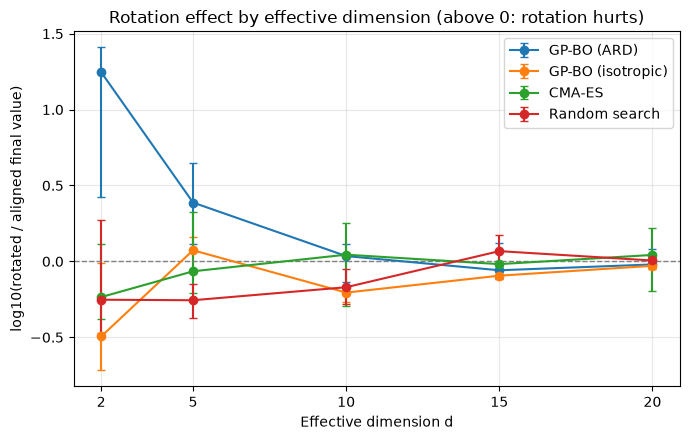

In [38]:
fig, ax = plt.subplots(figsize=(7, 4.5))

for method in available:
    values = pairs[pairs["method"] == method]
    stats = values.groupby("d")["log10_rotation_effect"].quantile([0.25, 0.5, 0.75]).unstack()
    ax.errorbar(
        stats.index,
        stats[0.5],
        yerr=[stats[0.5] - stats[0.25], stats[0.75] - stats[0.5]],
        marker="o",
        capsize=3,
        label=METHODS[method],
    )

ax.axhline(0, color="grey", linestyle="--", linewidth=1)
ax.set_xticks(EFFECTIVE_DIMS)
ax.set_xlabel("Effective dimension d")
ax.set_ylabel("log10(rotated / aligned final value)")
ax.set_title("Rotation effect by effective dimension (above 0: rotation hurts)")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## 6. H1: ARD-BO vs CMA-ES rotation penalty

Both methods solve the same problems, but a method seed means different things in BO and CMA-ES.
So each method's penalty is first averaged over its two method seeds, giving one penalty per problem (5 pairs per d).
H1 predicts **ARD penalty − CMA-ES penalty > 0**.

,penalty_ratio,pairs_larger,n_problem_pairs
d,,,
2,13.50,5,5
5,2.84,4,5
10,1.07,3,5
15,0.96,2,5
20,1.12,4,5


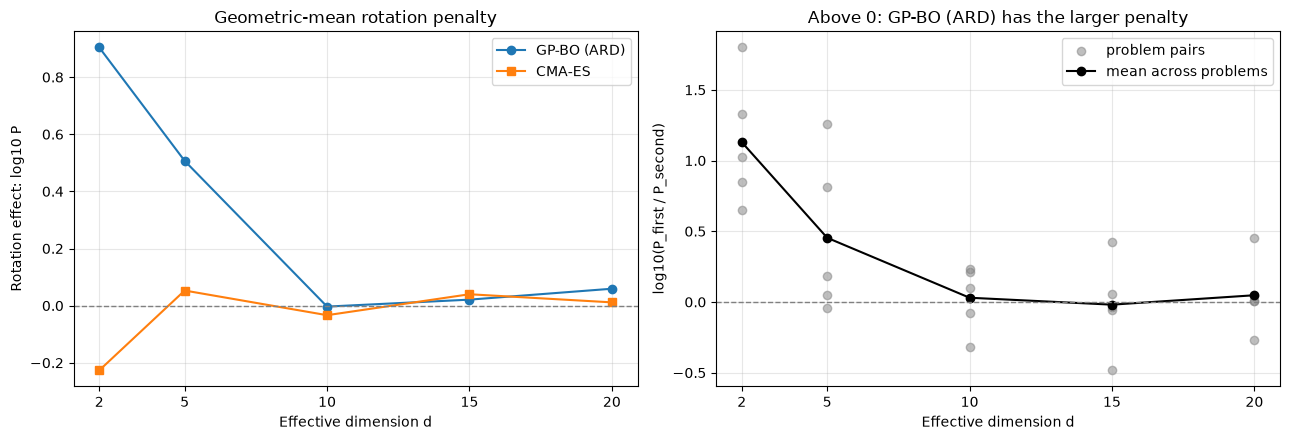

In [39]:
def plot_penalty_comparison(paired, first, second):
    """Left: each method's log10 P. Right: log10(P_first / P_second) per problem pair."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

    for method, marker in [(first, "o"), (second, "s")]:
        mean_effect = paired.groupby("d")[method].mean()
        ax1.plot(mean_effect.index, mean_effect, marker=marker, label=METHODS[method])

    ax1.set_ylabel("Rotation effect: log10 P")
    ax1.set_title("Geometric-mean rotation penalty")
    ax1.legend()

    difference = paired[first] - paired[second]
    ax2.scatter(
        difference.index.get_level_values("d"), difference,
        color="grey", alpha=0.5, label="problem pairs",
    )
    mean_difference = difference.groupby(level="d").mean()
    ax2.plot(mean_difference.index, mean_difference, marker="o", color="black", label="mean across problems")
    ax2.set_ylabel("log10(P_first / P_second)")
    ax2.set_title(f"Above 0: {METHODS[first]} has the larger penalty")
    ax2.legend()

    for ax in (ax1, ax2):
        ax.axhline(0, color="grey", linestyle="--", linewidth=1)
        ax.set_xticks(EFFECTIVE_DIMS)
        ax.set_xlabel("Effective dimension d")
        ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


# Convert natural-log effects to log10 for plotting.
# One value per method and problem, averaged over the two method seeds.
problem_penalty = (problem_log / np.log(10)).unstack("method")
h1 = problem_penalty[["bo_ard", "cmaes"]]

with pd.option_context("display.float_format", "{:.2f}".format):
    display(compare("bo_ard", "cmaes"))

plot_penalty_comparison(h1, "bo_ard", "cmaes")

## 7. H2: ARD-BO rotation penalty vs effective dimension

H2 predicts ARD's rotation penalty is larger at small d, where more coordinates are irrelevant in the aligned case.

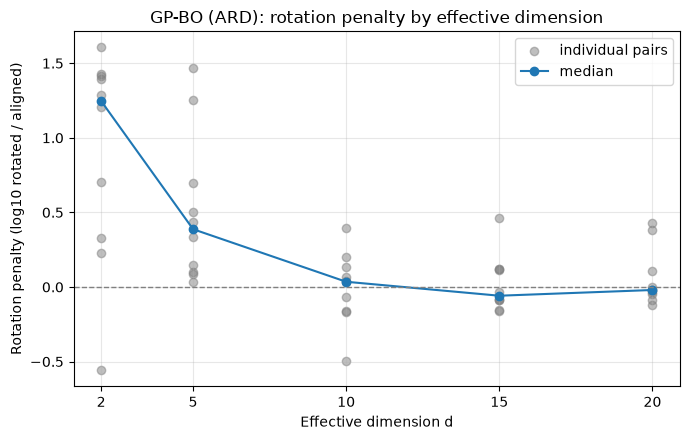

In [40]:
ard_pairs = pairs[pairs["method"] == "bo_ard"]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(
    ard_pairs["d"], ard_pairs["log10_rotation_effect"],
    color="grey", alpha=0.5, label="individual pairs",
)
median = ard_pairs.groupby("d")["log10_rotation_effect"].median()
ax.plot(median.index, median, marker="o", color="tab:blue", label="median")

ax.axhline(0, color="grey", linestyle="--", linewidth=1)
ax.set_xticks(EFFECTIVE_DIMS)
ax.set_xlabel("Effective dimension d")
ax.set_ylabel("Rotation penalty (log10 rotated / aligned)")
ax.set_title(f"{METHODS['bo_ard']}: rotation penalty by effective dimension")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## 8. H3: ARD-BO vs isotropic BO rotation penalty

ARD and isotropic BO share the same code and seeds (same initial points and candidate sets),
but are compared at problem level (seed-averaged, 5 pairs per d), the same as H1. H3 predicts **ARD penalty − isotropic penalty > 0**.

,penalty_ratio,pairs_larger,n_problem_pairs
d,,,
2,22.45,5,5
5,2.96,5,5
10,1.65,4,5
15,1.33,4,5
20,1.25,5,5


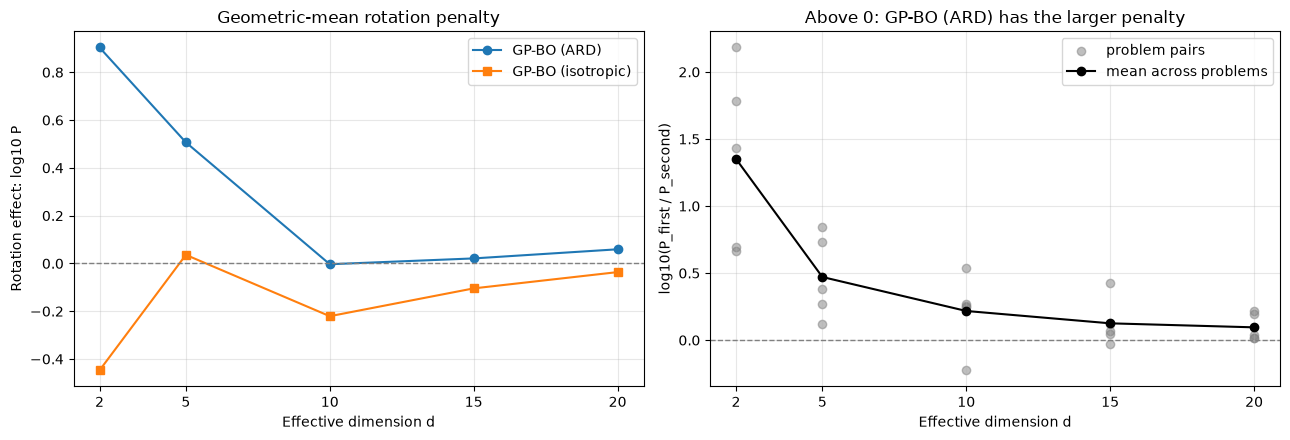

In [41]:
h3 = problem_penalty[["bo_ard", "isotropic_bo"]]

with pd.option_context("display.float_format", "{:.2f}".format):
    display(compare("bo_ard", "isotropic_bo"))

plot_penalty_comparison(h3, "bo_ard", "isotropic_bo")

### 8.1 Why: ARD length scales

Short length scale = coordinate treated as important. In the aligned case ARD should pick out the first d coordinates;
after rotation there is no coordinate structure to find.

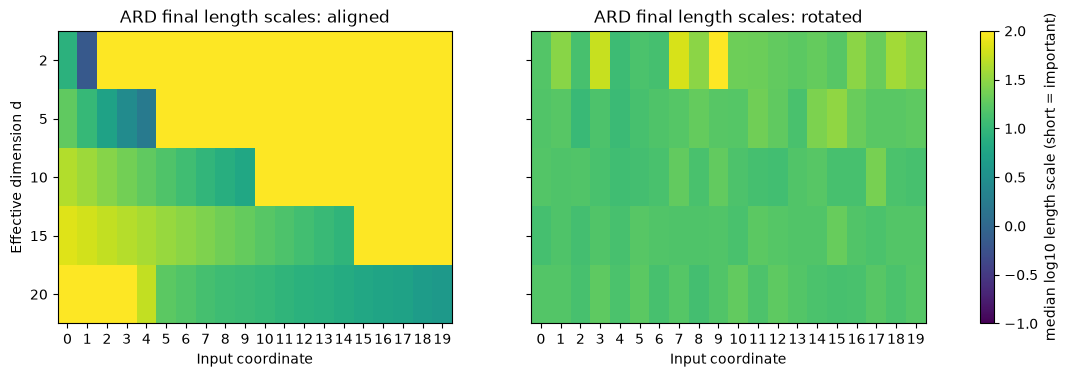

In [42]:
ard_final = final[final["method"] == "bo_ard"]
scale_columns = [f"length_scale{i}" for i in range(D)]

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)

for ax, orientation in zip(axes, ["aligned", "rotated"]):
    # Median log10 length scale per coordinate over the 10 runs per d.
    scales = (
        np.log10(ard_final[ard_final["orientation"] == orientation][scale_columns])
        .groupby(ard_final["d"])
        .median()
        .reindex(EFFECTIVE_DIMS)
    )
    image = ax.imshow(scales, aspect="auto", cmap="viridis", vmin=-1, vmax=2)
    ax.set_title(f"ARD final length scales: {orientation}")
    ax.set_xticks(range(D))
    ax.set_xlabel("Input coordinate")
    ax.set_yticks(range(len(EFFECTIVE_DIMS)))
    ax.set_yticklabels(EFFECTIVE_DIMS)

axes[0].set_ylabel("Effective dimension d")
fig.colorbar(image, ax=axes, label="median log10 length scale (short = important)")
plt.show()

## 9. Report figure for H1-H3
Use this single figure in report Section 4.2. Each line shows the mean of five problem effects, with two method-seed log ratios averaged within each problem. H1 and H3 compare ARD with the other methods; H2 examines the ARD line across dimensions. Positive values indicate worse performance after rotation. Variation and paired counts remain available in the existing H1/H3 analyses.

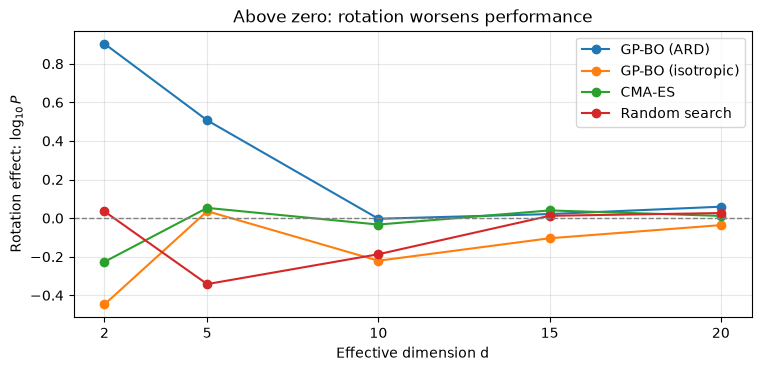

In [43]:
# One simple report figure for H1-H3. Use the report's mean log effects.
report_rotation = (problem_log / np.log(10)).groupby(["method", "d"]).mean()
fig, ax = plt.subplots(figsize=(7.5, 3.6), layout="constrained")
report_colours = {
    "bo_ard": "tab:blue", "isotropic_bo": "tab:orange",
    "cmaes": "tab:green", "random_search": "tab:red",
}
for method in available:
    effects = report_rotation.loc[method]
    ax.plot(
        effects.index, effects, marker="o", label=METHODS[method],
        color=report_colours[method],
    )
ax.axhline(0, color="grey", linestyle="--", linewidth=1)
ax.set_xticks(EFFECTIVE_DIMS)
ax.set_xlabel("Effective dimension d")
ax.set_ylabel(r"Rotation effect: $\log_{10}P$")
ax.set_title("Above zero: rotation worsens performance")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()


## 10. Additional context

### 10.1 Final value relative to CMA-ES

For each matched run, `log10(method / CMA-ES final value)`. Below 0 means the method beat CMA-ES.
Shows what the rotation penalty means in practice, e.g. whether rotation changes which method wins.

In [44]:
by_run = final.pivot_table(
    index=["d", "orientation", "problem_seed", "method_seed"],
    columns="method",
    values="best_so_far",
)

others = [m for m in available if m != "cmaes"]
relative = np.log10(by_run[others].div(by_run["cmaes"], axis=0))
relative = relative.melt(ignore_index=False, var_name="method", value_name="log10_vs_cmaes").reset_index()

relative_summary = (
    relative.groupby(["method", "d", "orientation"])["log10_vs_cmaes"]
    .agg(median="median", q25=q25, q75=q75)
    .join(
        relative.groupby(["method", "d", "orientation"])["log10_vs_cmaes"]
        .apply(lambda x: (x < 0).mean())
        .rename("fraction_beating_cmaes")
    )
    .reset_index()
)
relative_summary["method"] = relative_summary["method"].map(METHODS)

with pd.option_context("display.float_format", "{:.2f}".format):
    display(relative_summary)

,method,d,orientation,median,q25,q75,fraction_beating_cmaes
0,GP-BO (ARD),2,aligned,-1.19,-1.45,-1.02,1.00
1,GP-BO (ARD),2,rotated,-0.21,-0.44,0.48,0.60
2,GP-BO (ARD),5,aligned,-0.34,-0.64,-0.20,0.90
3,GP-BO (ARD),5,rotated,0.19,-0.29,0.37,0.40
4,GP-BO (ARD),10,aligned,0.52,0.29,0.59,0.10
5,GP-BO (ARD),10,rotated,0.46,0.29,0.64,0.00
6,GP-BO (ARD),15,aligned,0.72,0.63,0.78,0.00
7,GP-BO (ARD),15,rotated,0.62,0.53,0.88,0.00
8,GP-BO (ARD),20,aligned,0.94,0.82,1.13,0.00
9,GP-BO (ARD),20,rotated,0.90,0.80,1.20,0.00


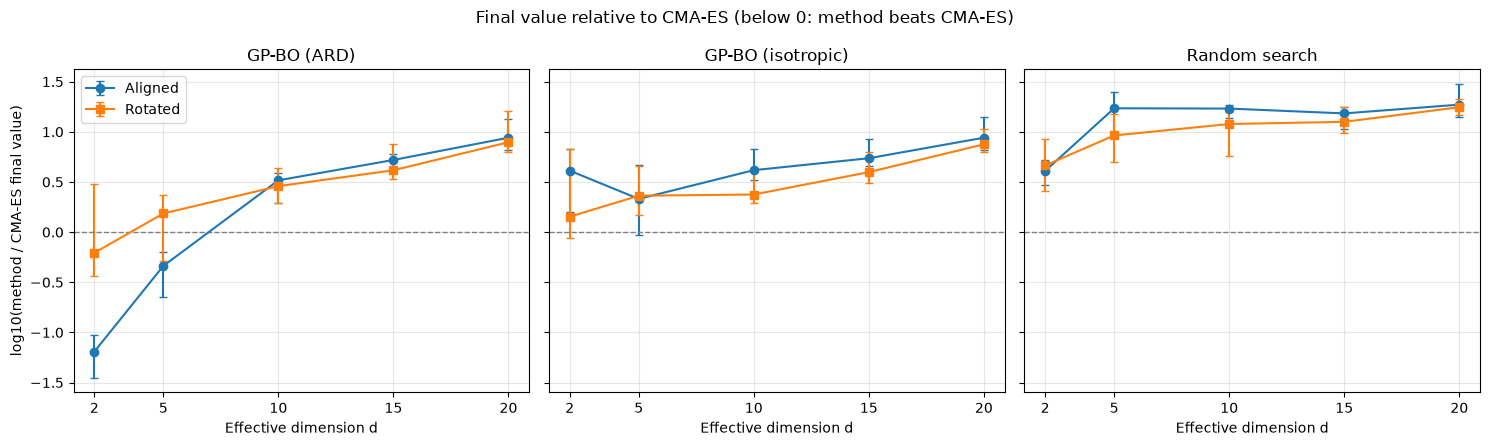

In [45]:
fig, axes = plt.subplots(1, len(others), figsize=(5 * len(others), 4.5), sharey=True)

for ax, method in zip(np.atleast_1d(axes), others):
    for orientation, marker in [("aligned", "o"), ("rotated", "s")]:
        values = relative[(relative["method"] == method) & (relative["orientation"] == orientation)]
        stats = values.groupby("d")["log10_vs_cmaes"].quantile([0.25, 0.5, 0.75]).unstack()
        ax.errorbar(
            stats.index, stats[0.5],
            yerr=[stats[0.5] - stats[0.25], stats[0.75] - stats[0.5]],
            marker=marker, capsize=3, label=orientation.capitalize(),
        )

    ax.axhline(0, color="grey", linestyle="--", linewidth=1)
    ax.set_xticks(EFFECTIVE_DIMS)
    ax.set_xlabel("Effective dimension d")
    ax.set_title(METHODS[method])
    ax.grid(True, alpha=0.3)

np.atleast_1d(axes)[0].set_ylabel("log10(method / CMA-ES final value)")
np.atleast_1d(axes)[0].legend()
fig.suptitle("Final value relative to CMA-ES (below 0: method beats CMA-ES)")
plt.tight_layout()
plt.show()

### 10.2 ARD vs isotropic final values

`log10(isotropic / ARD final value)` per matched run. Above 0 means ARD found the lower value.

In [46]:
if {"bo_ard", "isotropic_bo"} <= set(available):
    kernels = final[final["method"].isin(["bo_ard", "isotropic_bo"])].pivot_table(
        index=["d", "orientation", "problem_seed", "method_seed"],
        columns="method",
        values="best_so_far",
    )

    # > 0: ARD found a better (lower) final value than isotropic.
    kernels["log10_iso_over_ard"] = np.log10(kernels["isotropic_bo"] / kernels["bo_ard"])

    kernel_summary = (
        kernels.groupby(["d", "orientation"])["log10_iso_over_ard"]
        .agg(median="median", q25=q25, q75=q75)
        .unstack("orientation")
    )
    with pd.option_context("display.float_format", "{:.2f}".format):
        display(kernel_summary)
else:
    print("Needs both bo_ard and isotropic_bo results; available:", available)

median             q25             q75        
orientation aligned rotated aligned rotated aligned rotated
d                                                          
2              1.61    0.35    1.17    0.29    2.28    0.54
5              0.62    0.35    0.50   -0.09    0.95    0.65
10             0.23    0.00    0.18    0.00    0.31    0.00
15             0.01    0.00    0.00    0.00    0.15    0.00
20             0.00    0.00    0.00    0.00    0.03    0.00

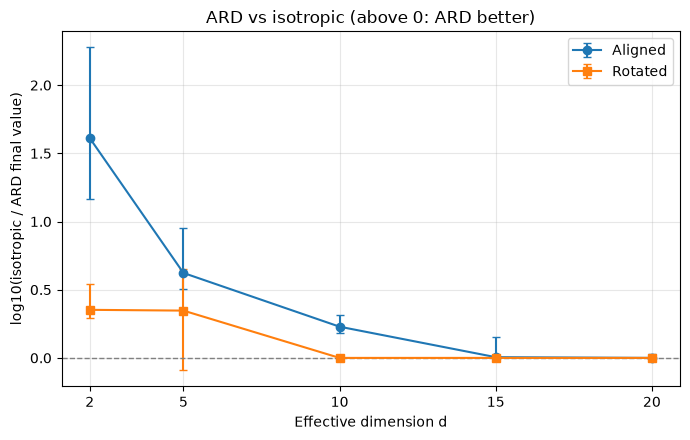

In [47]:
fig, ax = plt.subplots(figsize=(7, 4.5))

for orientation, marker in [("aligned", "o"), ("rotated", "s")]:
    stats = kernel_summary[("median", orientation)]
    lower = stats - kernel_summary[("q25", orientation)]
    upper = kernel_summary[("q75", orientation)] - stats
    ax.errorbar(
        stats.index, stats, yerr=[lower, upper],
        marker=marker, capsize=3, label=orientation.capitalize(),
    )

ax.axhline(0, color="grey", linestyle="--", linewidth=1)
ax.set_xticks(EFFECTIVE_DIMS)
ax.set_xlabel("Effective dimension d")
ax.set_ylabel("log10(isotropic / ARD final value)")
ax.set_title("ARD vs isotropic (above 0: ARD better)")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## 11. Runtime

In [48]:
runtime = (
    final.groupby(["method", "d"])["runtime_s"]
    .median()
    .unstack("d")
    .rename(index=METHODS)
)
print("Median runtime per run (seconds)")
with pd.option_context("display.float_format", "{:.2f}".format):
    display(runtime)

Median runtime per run (seconds)


d,2,5,10,15,20
method,,,,,
GP-BO (ARD),338.81,315.48,347.90,327.98,383.46
CMA-ES,0.03,0.03,0.03,0.03,0.03
GP-BO (isotropic),25.26,25.30,32.16,27.08,26.64
Random search,0.01,0.01,0.01,0.01,0.01


## 12. Supplementary equal-curvature experiment
Compare the two BO variants using the same median and interquartile-range summary as the main performance figure. Lower objective values are better. Error bars describe the spread across ten runs, not confidence intervals.

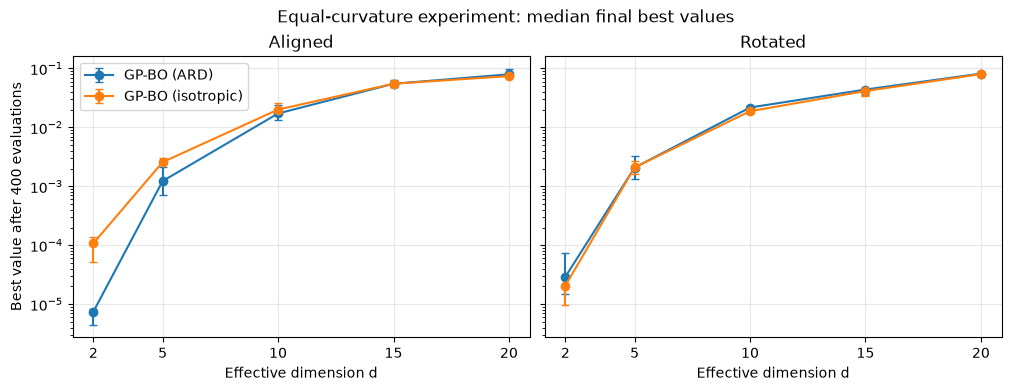

In [49]:
# Same final-performance summary as the main experiment: median and IQR.
SUPP_METHODS = {
    "bo_ard_equal_curvature": "GP-BO (ARD)",
    "isotropic_bo_equal_curvature": "GP-BO (isotropic)",
}
supp_df = load_results(RESULTS_DIR / "supplementary_equal_curvature", SUPP_METHODS)
supp_final = supp_df[supp_df["evaluation"] == BUDGET].copy()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True, layout="constrained")
for ax, orientation in zip(axes, ["aligned", "rotated"]):
    for method, label in SUPP_METHODS.items():
        values = supp_final[
            (supp_final["method"] == method)
            & (supp_final["orientation"] == orientation)
        ]
        stats = values.groupby("d")["best_so_far"].quantile([0.25, 0.5, 0.75]).unstack()
        ax.errorbar(
            stats.index, stats[0.5],
            yerr=[stats[0.5] - stats[0.25], stats[0.75] - stats[0.5]],
            marker="o", capsize=3, label=label,
        )
    ax.set_yscale("log")
    ax.set_xticks(EFFECTIVE_DIMS)
    ax.set_xlabel("Effective dimension d")
    ax.set_title(orientation.capitalize())
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel(f"Best value after {BUDGET} evaluations")
axes[0].legend()
fig.suptitle("Equal-curvature experiment: median final best values")
plt.show()


### 12.1 Supplementary ARD length scales
Compare with Section 8.1 using the same colour scale. Similar colours across a row indicate similar fitted length scales across coordinates. This is supporting analysis; the report need not include both sets of heatmaps.

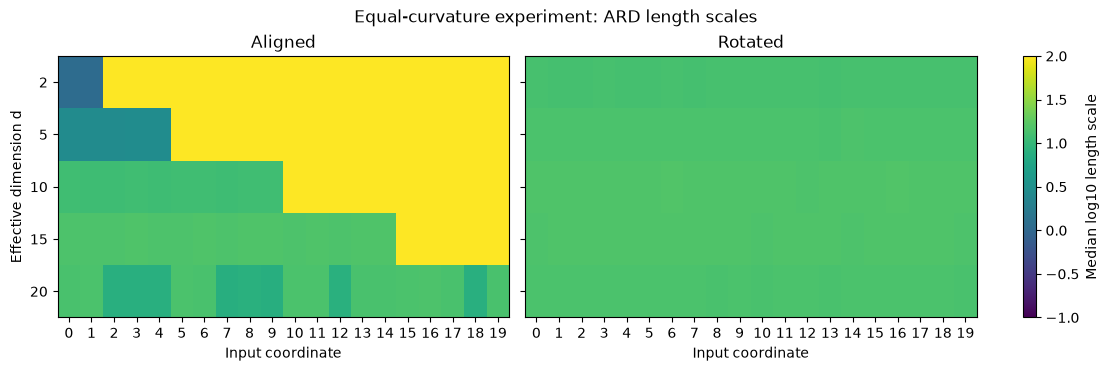

In [50]:
# Use the same length-scale heatmap and colour scale as Section 8.1.
supp_ard_final = supp_final[supp_final["method"] == "bo_ard_equal_curvature"]
supp_scale_columns = [f"length_scale{i}" for i in range(D)]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True, layout="constrained")
for ax, orientation in zip(axes, ["aligned", "rotated"]):
    values = supp_ard_final[supp_ard_final["orientation"] == orientation]
    scales = np.log10(values[supp_scale_columns]).groupby(values["d"]).median()
    image = ax.imshow(
        scales.reindex(EFFECTIVE_DIMS), aspect="auto", cmap="viridis", vmin=-1, vmax=2,
    )
    ax.set_title(orientation.capitalize())
    ax.set_xticks(range(D))
    ax.set_xlabel("Input coordinate")
    ax.set_yticks(range(len(EFFECTIVE_DIMS)))
    ax.set_yticklabels(EFFECTIVE_DIMS)
axes[0].set_ylabel("Effective dimension d")
fig.colorbar(image, ax=axes, label="Median log10 length scale")
fig.suptitle("Equal-curvature experiment: ARD length scales")
plt.show()


### 12. 2 Median objective values for the report
This compact table compares main and supplementary results at d = 2 and 5, where the main rotated ARD advantage motivates the follow-up. Compare ARD with isotropic BO within each row and orientation. Lower is better. The objective families change both weights and rotation construction, so their absolute values are not a controlled measure of curvature alone. All dimensions remain available in the full table variable and supplementary plots.

In [51]:
# Median final values: compare the two methods within each objective family.
main_table_data = final[final["method"].isin(["bo_ard", "isotropic_bo"])].copy()
main_table_data["Objective"] = "Weighted"
supp_table_data = supp_final.copy()
supp_table_data["Objective"] = "Equal curvature"
supp_table_data["method"] = supp_table_data["method"].map({
    "bo_ard_equal_curvature": "bo_ard",
    "isotropic_bo_equal_curvature": "isotropic_bo",
})
objective_values = pd.concat([main_table_data, supp_table_data], ignore_index=True)
median_objective_table = objective_values.pivot_table(
    index=["d", "Objective"], columns=["orientation", "method"],
    values="best_so_far", aggfunc="median",
)
median_objective_table = median_objective_table.reindex(
    index=pd.MultiIndex.from_product(
        [EFFECTIVE_DIMS, ["Weighted", "Equal curvature"]], names=["d", "Objective"]
    ),
    columns=pd.MultiIndex.from_product(
        [["aligned", "rotated"], ["bo_ard", "isotropic_bo"]]
    ),
)
median_objective_table.columns = [
    "Aligned: ARD", "Aligned: isotropic", "Rotated: ARD", "Rotated: isotropic"
]
# Keep all dimensions in median_objective_table; show the low-dimensional
# follow-up in the compact report table. The plots above show every dimension.
print("Median final best objective values (lower is better; 10 runs per setting)")
with pd.option_context("display.float_format", "{:.2e}".format):
    display(median_objective_table.loc[[2, 5]])


Median final best objective values (lower is better; 10 runs per setting)


Aligned: ARD  Aligned: isotropic  Rotated: ARD  \
d Objective                                                         
2 Weighted             1.20e-06            1.24e-04      2.10e-05   
  Equal curvature      7.48e-06            1.08e-04      2.91e-05   
5 Weighted             4.33e-04            1.88e-03      1.34e-03   
  Equal curvature      1.23e-03            2.57e-03      2.08e-03   

                   Rotated: isotropic  
d Objective                            
2 Weighted                   4.92e-05  
  Equal curvature            2.07e-05  
5 Weighted                   2.23e-03  
  Equal curvature            2.09e-03